<a href="https://colab.research.google.com/github/ssinmani/Project_K-Means_ECG/blob/main/warmup_linear_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [30]:
import numpy as np
import matplotlib.pyplot as plt
import math


In [31]:
x_train = np.random.uniform (0,10,50)
y_train = 3 * x_train + 2 + np.random.normal (0,1,50)

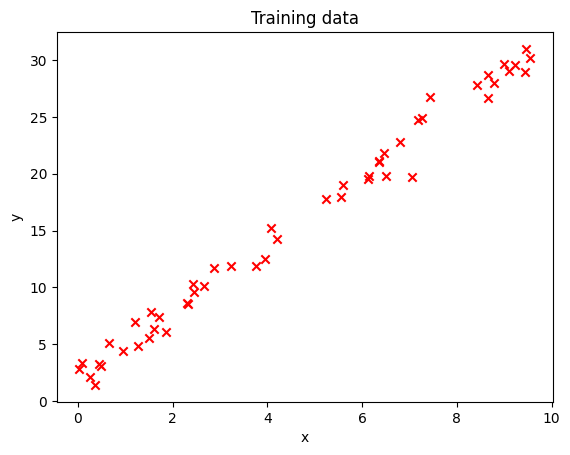

In [32]:
plt.scatter(x_train ,y_train, marker='x', c='r')
plt.title ("Training data");
plt.xlabel("x");
plt.ylabel("y");


In [33]:
def compute_cost (x ,y ,w ,b ):
  m = x.shape[0]
  cost_sum = 0
  for i in range(m):
          f_wb = w * x[i] + b
          cost = (f_wb - y[i]) ** 2
          cost_sum = cost_sum + cost
  total_cost = (1 / (2 * m)) * cost_sum

  return total_cost

In [34]:
print(compute_cost(x_train, y_train, 3, 2))
print(compute_cost(x_train, y_train, 0, 0))

0.5255994474875161
166.25939563623137


In [35]:
def compute_gradient(x, y, w, b):
    m = x.shape[0]
    dj_dw = 0
    dj_db = 0

    for i in range(m):
        f_wb = w * x[i] + b
        dj_dw_i = (f_wb - y[i]) * x[i]
        dj_db_i = f_wb - y[i]
        dj_db += dj_db_i
        dj_dw += dj_dw_i
    dj_dw = dj_dw / m
    dj_db = dj_db / m

    return dj_dw, dj_db

In [36]:
dw, db = compute_gradient(x_train, y_train, 0, 0)
print(dw, db)

-100.6299261178459 -15.629325125943092


In [37]:
def gradient_descent(x, y, w_in, b_in, alpha, num_iters, cost_function, gradient_function):
    J_history = []
    p_history = []
    b = b_in
    w = w_in

    for i in range(num_iters):
        # Calculate the gradient and update the parameters using gradient_function
        dj_dw, dj_db = gradient_function(x, y, w , b)

        # Update Parameters using equation (3) above
        b = b - alpha * dj_db
        w = w - alpha * dj_dw

        # Save cost J at each iteration
        if i<100000:      # prevent resource exhaustion
            J_history.append( cost_function(x, y, w , b))
            p_history.append([w,b])
        # Print cost every at intervals 10 times or as many iterations if < 10
        if i% math.ceil(num_iters/10) == 0:
            print(f"Iteration {i:4}: Cost {J_history[-1]:0.2e} ",
                  f"dj_dw: {dj_dw: 0.3e}, dj_db: {dj_db: 0.3e}  ",
                  f"w: {w: 0.3e}, b:{b: 0.5e}")

    return w, b, J_history, p_history #return w and J,w history for graphing

In [39]:
w, b, J_history, p_history = gradient_descent(
    x_train, y_train, 0, 0, 0.01, 1000, compute_cost, compute_gradient)
print(f"Final: w = {w:.3f}, b = {b:.3f}")

Iteration    0: Cost 7.88e+01  dj_dw: -1.006e+02, dj_db: -1.563e+01   w:  1.006e+00, b: 1.56293e-01
Iteration  100: Cost 7.04e-01  dj_dw:  5.047e-02, dj_db: -3.350e-01   w:  3.152e+00, b: 8.80898e-01
Iteration  200: Cost 6.19e-01  dj_dw:  3.696e-02, dj_db: -2.453e-01   w:  3.109e+00, b: 1.16825e+00
Iteration  300: Cost 5.74e-01  dj_dw:  2.707e-02, dj_db: -1.796e-01   w:  3.077e+00, b: 1.37870e+00
Iteration  400: Cost 5.49e-01  dj_dw:  1.982e-02, dj_db: -1.316e-01   w:  3.054e+00, b: 1.53281e+00
Iteration  500: Cost 5.36e-01  dj_dw:  1.452e-02, dj_db: -9.635e-02   w:  3.037e+00, b: 1.64567e+00
Iteration  600: Cost 5.29e-01  dj_dw:  1.063e-02, dj_db: -7.056e-02   w:  3.025e+00, b: 1.72833e+00
Iteration  700: Cost 5.26e-01  dj_dw:  7.785e-03, dj_db: -5.167e-02   w:  3.015e+00, b: 1.78886e+00
Iteration  800: Cost 5.24e-01  dj_dw:  5.701e-03, dj_db: -3.784e-02   w:  3.009e+00, b: 1.83319e+00
Iteration  900: Cost 5.22e-01  dj_dw:  4.175e-03, dj_db: -2.771e-02   w:  3.004e+00, b: 1.86565e+00


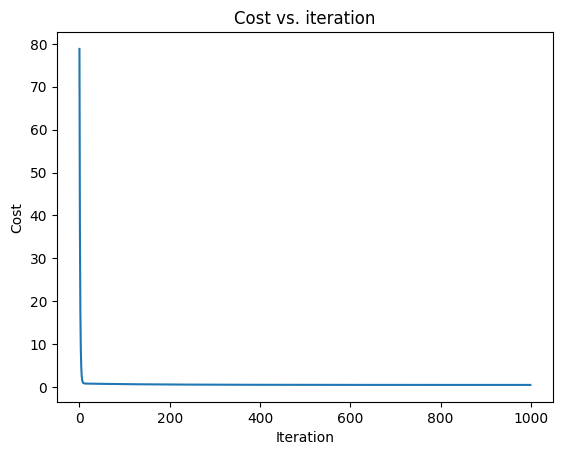

In [40]:
plt.plot(J_history)
plt.title("Cost vs. iteration")
plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.show()

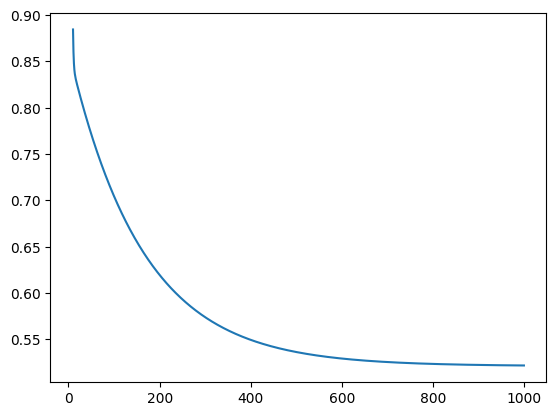

In [41]:
plt.plot(range(10, 1000), J_history[10:])
plt.show()